# Baseline model

The default loads cached results without training or inference. Set `retrain = True` to train afresh for 20 epochs on a CUDA GPU and overwrite `data/model_runs/baseline/`.

## Imports and settings

In [1]:
%matplotlib inline
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / 'scripts'))
import hashlib
import json
import platform
import torch
import numpy as np
from torch import nn
from model_components import FaceCNN
from model_components import Classifier
import os
import random
from data import DATA_DIR, _load_splits

REPORT_DIR = Path.cwd().resolve()
DEFAULT_CONFIG = dict(seed=0, deterministic=True, in_channels=7, embedding_dim=64,
                      hidden_dim=128, num_classes=16, num_epochs=20,
                      learning_rate=0.001, batch_size=128, sample_limit=None)



In [2]:
retrain = False

## Face CNN and classifier

The shared face encoder and classifier are reused across the model ladder.

In [3]:
face_cnn = FaceCNN(embedding_dim=64, in_channels=7)
classifier = Classifier(embedding_dim=64, hidden_dim=128, num_classes=16)
model = nn.Sequential(face_cnn, classifier)
print(model)

Sequential(
  (0): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_ru

## Training procedure

Defining this function does not start training. It is called only when `retrain = True`.

In [4]:
def _train(config, run_dir):
    seed = config['seed']
    deterministic = config['deterministic']
    in_channels, embedding_dim = config['in_channels'], config['embedding_dim']
    hidden_dim, num_classes = config['hidden_dim'], config['num_classes']
    device = torch.device(config['device'])
    import csv
    from pathlib import Path

    from torch.utils.data import Dataset, DataLoader
    from tqdm.auto import tqdm

    from data import DATA_DIR, _load_sample, _load_splits
    from model_evaluation import evaluate, save_training_summary

    num_epochs = config["num_epochs"]
    learning_rate = config["learning_rate"]
    batch_size = config["batch_size"]
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)

    use_amp = device.type == "cuda"
    if use_amp:
        torch.backends.cudnn.benchmark = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    class FaceDataset(Dataset):
        def __init__(self, split):
            self.sample_ids = _load_splits()[split]
            if config["sample_limit"] is not None:
                self.sample_ids = self.sample_ids[:config["sample_limit"]]
            self.samples = []
            # Load only once, rather than reading graphs/JSON every epoch.
            for sample_id in tqdm(self.sample_ids, desc=f"Cache {split}"):
                sample = _load_sample(sample_id)
                grids = sample["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
                labels = torch.tensor([face["segment"]["index"]
                                       for face in sample["faces"]], dtype=torch.long)
                self.samples.append((grids, labels))

        def __len__(self):
            return len(self.samples)

        def __getitem__(self, index):
            return self.samples[index]


    def collate_faces(batch):
        grids, labels = zip(*batch)
        return torch.cat(grids), torch.cat(labels)


    train_dataset = FaceDataset("train")
    evaluation_dataset = FaceDataset("validation")

    loader_options = dict(batch_size=batch_size, collate_fn=collate_faces,
                          num_workers=0, pin_memory=use_amp)
    train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
    evaluation_loader = DataLoader(evaluation_dataset, shuffle=False, **loader_options)

    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(deterministic)
    torch.backends.cudnn.deterministic = deterministic
    face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    classifier = Classifier(embedding_dim, hidden_dim, num_classes)
    model = nn.Sequential(face_cnn, classifier)
    model = model.to(device)
    if use_amp:
        model = model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    batch_history = []
    global_step = 0

    run_config = dict(stage="baseline", seed=seed, deterministic=deterministic,
                      in_channels=in_channels, embedding_dim=embedding_dim,
                      hidden_dim=hidden_dim, num_classes=num_classes,
                      learning_rate=learning_rate, batch_size=batch_size,
                      mixed_precision=use_amp, train_sample_ids=train_dataset.sample_ids,
                      validation_sample_ids=evaluation_dataset.sample_ids)
    def move_batch(grids, labels):
        grids = grids.to(device, non_blocking=True)
        if use_amp:
            grids = grids.contiguous(memory_format=torch.channels_last)
        return grids, labels.to(device, non_blocking=True)


    @torch.no_grad()
    def validation_metrics():
        model.eval()
        total_loss = torch.zeros((), device=device)
        total_correct = torch.zeros((), device=device, dtype=torch.long)
        total_faces = 0
        for grids, labels in tqdm(evaluation_loader, desc="Validation", leave=False):
            grids, labels = move_batch(grids, labels)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(grids)
                loss = loss_fn(logits, labels)
            total_loss += loss.detach() * labels.numel()
            total_correct += (logits.argmax(1) == labels).sum()
            total_faces += labels.numel()
        return total_loss.item() / total_faces, total_correct.item() / total_faces


    checkpoint_dir = run_dir / f"epoch_{num_epochs:03d}"
    for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):
        model.train()
        epoch_losses, epoch_correct, epoch_sizes = [], [], []
        for grids, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
            grids, labels = move_batch(grids, labels)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                logits = model(grids)
                loss = loss_fn(logits, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            # Keep small statistics on GPU; copy once per epoch, not every batch.
            epoch_losses.append(loss.detach())
            epoch_correct.append((logits.detach().argmax(1) == labels).sum())
            epoch_sizes.append(labels.numel())

        losses = torch.stack(epoch_losses).cpu().tolist()
        correct = torch.stack(epoch_correct).sum().item()
        faces = sum(epoch_sizes)
        for batch_index, (batch_loss, count) in enumerate(zip(losses, epoch_sizes), 1):
            global_step += 1
            batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                      loss=batch_loss, faces=count))
        train_loss = sum(loss * count for loss, count in zip(losses, epoch_sizes)) / faces
        train_accuracy = correct / faces

        validation_loss, validation_accuracy = validation_metrics()
        row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
                   train_accuracy=train_accuracy, validation_loss=validation_loss,
                   validation_accuracy=validation_accuracy)
        history.append(row)
        with (run_dir / "history.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(row))
            writer.writeheader()
            writer.writerows(history)
        tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
                   f"accuracy {train_accuracy:.2%} | validation loss {validation_loss:.4f}, "
                   f"accuracy {validation_accuracy:.2%}")
        with (run_dir / "batch_loss.csv").open("w", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
            writer.writeheader()
            writer.writerows(batch_history)

    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    torch.save(dict(epoch=num_epochs, model_state_dict=model.state_dict(),
                    config=run_config, history=history), checkpoint_dir / 'checkpoint.pt')

    # Full prediction collection happens only once, for the final model.
    # Use the evaluator's float32 path for saved final results on both splits.
    train_evaluation_loader = DataLoader(train_dataset, shuffle=False, **loader_options)
    final_train_results = evaluate(model, train_evaluation_loader,
                                   None, device=device,
                                   sample_ids=train_dataset.sample_ids, split="train")
    save_training_summary(final_train_results, checkpoint_dir / 'train_metrics.json')
    final_validation_results = evaluate(model, evaluation_loader,
                                        checkpoint_dir / "validation_predictions.pt", device=device,
                                        sample_ids=evaluation_dataset.sample_ids, split="validation")
    print(f"Finished. Final predictions and checkpoints: {run_dir}")

    return dict(run_dir=str(run_dir), final_epoch=num_epochs, train_accuracy=final_train_results["accuracy"], validation_accuracy=final_validation_results["accuracy"])

## Load cached results or explicitly retrain

In [5]:
run_dir = REPORT_DIR / 'data' / 'model_runs' / 'baseline'
result_path = run_dir / 'result.json'

if not retrain:
    if not result_path.is_file():
        raise FileNotFoundError('Cached baseline results are missing. No training was started.')
    run = json.loads(result_path.read_text())
    for name, expected in run['files'].items():
        path = run_dir / name
        if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != expected:
            raise RuntimeError(f'Cached file is missing or changed: {path}. No training was started.')
    run = {**run, 'run_dir': str(run_dir), 'cached': True}
    print(f'Loaded cached baseline: {run_dir}')
else:
    if not torch.cuda.is_available():
        raise RuntimeError('Retraining requires a CUDA GPU. Keep retrain=False to view cached results.')
    import shutil
    config = {**DEFAULT_CONFIG, 'device': 'cuda'}
    if run_dir.exists():
        shutil.rmtree(run_dir)
    run_dir.mkdir(parents=True)
    (run_dir / 'config.json').write_text(json.dumps(config, indent=2) + '\n')
    run = _train(config, run_dir)
    from model_evaluation import compact_validation_cache
    compact_validation_cache(run_dir, run["final_epoch"])
    from data import corrected_label
    names = {}
    for annotation in (DATA_DIR / 'labels').glob('*.json'):
        for face in json.loads(annotation.read_text())['body']['faces']:
            segment = face['segment']
            names[str(segment['index'])] = corrected_label(segment['name'])
        if len(names) == 16:
            break
    files = {path.relative_to(run_dir).as_posix(): hashlib.sha256(path.read_bytes()).hexdigest()
             for path in run_dir.rglob('*') if path.is_file()}
    run.update(config=config, class_names=names, files=files, cached=False)
    result_path.write_text(json.dumps(run, indent=2) + '\n')

Loaded cached baseline: /Users/yongjun/Workspace/NUS/CS5284/project/report/data/model_runs/baseline


## Cached training history

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data import corrected_label

root = Path(run['run_dir'])
final = root / f"epoch_{run['final_epoch']:03d}"
if (root / 'history.csv').exists():
    history = pd.read_csv(root / 'history.csv')
else:
    checkpoint = torch.load(final / 'checkpoint.pt', map_location='cpu', weights_only=True)
    history = pd.DataFrame(checkpoint['history'])

/Users/yongjun/miniconda3/envs/gnn_report/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


### Loss and accuracy plots

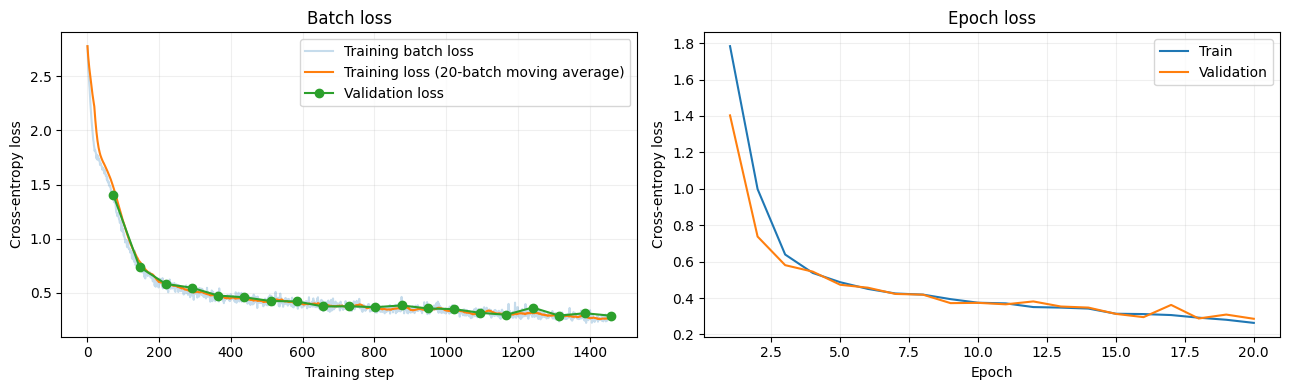

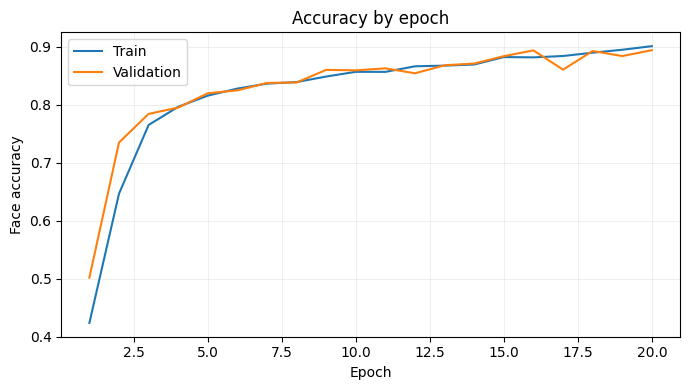

In [7]:
batch_log = pd.read_csv(root / 'batch_loss.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(batch_log['step'], batch_log['loss'], alpha=0.25, label='Training batch loss')
axes[0].plot(batch_log['step'], batch_log['loss'].rolling(20, min_periods=1).mean(),
             label='Training loss (20-batch moving average)')
axes[0].plot(history['step'], history['validation_loss'], marker='o', label='Validation loss')
axes[0].set(xlabel='Training step', ylabel='Cross-entropy loss', title='Batch loss')
for split in ['train', 'validation']:
    axes[1].plot(history['epoch'], history[f'{split}_loss'], label=split.capitalize())
axes[1].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Epoch loss')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
for split in ['train', 'validation']:
    ax.plot(history['epoch'], history[f'{split}_accuracy'], label=split.capitalize())
ax.set(xlabel='Epoch', ylabel='Face accuracy', title='Accuracy by epoch')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Final cached results

Overall mean IoU includes stock. Per-class results use the reviewed names; recall is the fraction of faces of that class classified correctly.

In [8]:
from model_evaluation import read_cached_metrics
summary, per_class = read_cached_metrics(root, run['final_epoch'], run['class_names'])
display(summary.style.format({'faces': '{:,}', 'loss': '{:.4f}', 'accuracy': '{:.2%}', 'mean_iou': '{:.2%}'}))
summary.to_csv(root / 'summary.csv')
per_class.to_csv(root / 'per_class_metrics.csv', index=False)


,faces,loss,accuracy,mean_iou
split,,,,
train,"209,847",0.2693,89.84%,80.17%
validation,"70,255",0.2863,89.44%,79.42%


### Per-class results

In [9]:
for split in ['train', 'validation']:
    print(f"{split.capitalize()} — per-class results")
    table = per_class.loc[per_class['split'] == split].set_index(['class_index', 'class_name'])
    display(table[['support', 'recall', 'precision', 'iou']].style.format(
        {'support': '{:,}', 'recall': '{:.2%}', 'precision': '{:.2%}', 'iou': '{:.2%}'}))

Train — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,"2,927",99.86%,100.00%,99.86%
1,triangular_passage,"9,605",58.54%,77.76%,50.15%
2,rectangular_passage,"13,077",83.76%,84.25%,72.42%
3,6sides_passage,"19,859",88.98%,83.85%,75.97%
4,triangular_through_slot,"5,778",99.95%,99.86%,99.81%
5,rectangular_through_slot,"8,508",80.36%,88.24%,72.59%
6,rectangular_through_step,"5,630",85.54%,91.42%,79.18%
7,2sides_through_step,"8,010",99.98%,95.73%,95.71%
8,slanted_through_step,"5,318",97.29%,96.15%,93.65%


Validation — per-class results


,,support,recall,precision,iou
class_index,class_name,,,,
0,chamfer,924,99.46%,100.00%,99.46%
1,triangular_passage,"2,985",58.29%,76.32%,49.36%
2,rectangular_passage,"4,390",81.66%,83.55%,70.35%
3,6sides_passage,"6,804",88.79%,84.14%,76.05%
4,triangular_through_slot,"1,892",99.95%,99.47%,99.42%
5,rectangular_through_slot,"2,883",78.98%,87.95%,71.27%
6,rectangular_through_step,"1,804",85.70%,90.41%,78.56%
7,2sides_through_step,"2,730",99.89%,95.65%,95.55%
8,slanted_through_step,"1,660",97.05%,96.64%,93.88%
